# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 6b: BiLSTM - Skema 2 "Tokenizer"
Tokenizer subword IndoBERT -> embedding layer IndoBERT 768-dim (frozen) -> BiLSTM (ditraining) -> state akhir kedua arah -> Dropout -> Fully Connected -> softmax

Yang dibekukan hanya embedding layer; BiLSTM dan Linear tetap dilatih. Arsitektur dan hyperparameter sama dengan 06a.

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`, `utils_embedding.py`
- Output: `outputs/bilstm_tokenizer_val_results.json`, `outputs/models/bilstm_tokenizer.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [ ]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Fungsi Skema 2 (tokenizer subword + embedding frozen IndoBERT); utils_embedding.py
from utils_embedding import MODEL_NAME, get_device, load_tokenizer_and_frozen_embedding, encode_subword

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/bilstm_tokenizer_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Skema 2: tokenizer subword + embedding layer IndoBERT pre-trained (frozen). Lihat utils_embedding.py
MAX_LEN = 128 # panjang maksimum dalam token subword; lihat persentase terpotong di Step 2

# Hyperparameter tetap, sama dengan versi Skema 1 (tanpa tuning)
HIDDEN_DIM = 128 # unit LSTM per arah (BiLSTM -> 256 setelah digabung)
CLIP_NORM = 1.0 # gradient clipping (standar untuk LSTM)
DROPOUT = 0.5
BATCH_SIZE = 64
EPOCHS = 15
LR = 1e-3 # Adam


for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train = torch.tensor([label_map[l] for l in train_df[LABEL_COL]], dtype=torch.long)
y_val = torch.tensor([label_map[l] for l in val_df[LABEL_COL]], dtype=torch.long)
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenizer subword IndoBERT & embedding layer frozen
Tokenizer dan tabel embedding diambil dari `indobenchmark/indobert-base-p1`.  
Hanya saja encoder transformer-nya tidak dipakai.

In [ ]:
tokenizer, emb_layer = load_tokenizer_and_frozen_embedding(MODEL_NAME)
PAD_ID = tokenizer.pad_token_id
print(f"Checkpoint: {MODEL_NAME} | vocab subword: {tokenizer.vocab_size} | embedding: {tuple(emb_layer.weight.shape)}")
print("Embedding beku (requires_grad):", emb_layer.weight.requires_grad)
assert not emb_layer.weight.requires_grad

contoh = train_df[TEXT_COL].iloc[0]
print("\nContoh teks:", contoh[:80])
print("Subword:", tokenizer.tokenize(contoh)[:12])

X_train, M_train = encode_subword(train_df[TEXT_COL].tolist(), tokenizer, MAX_LEN)
X_val, M_val = encode_subword(val_df[TEXT_COL].tolist(), tokenizer, MAX_LEN)

# Berapa banyak teks terpotong? (cek panjang subword asli di train)
len_full = np.array([len(x) for x in tokenizer(train_df[TEXT_COL].tolist(), add_special_tokens=False)["input_ids"]])
print(f"Panjang subword train: rata-rata {len_full.mean():.1f} | persentil 95 = {np.percentile(len_full, 95):.0f} | maks = {len_full.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {(len_full > MAX_LEN).mean()*100:.2f}%")
print("Bentuk tensor -> X_train:", tuple(X_train.shape), "| X_val:", tuple(X_val.shape))

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Checkpoint: indobenchmark/indobert-base-p1 | vocab subword: 30521 | embedding: (50000, 768)
Embedding beku (requires_grad): False

Contoh teks: 365. kalau mau gestun limit kamu di spaylater, gopay coin, gopaylater, akulaku, 
Subword: ['365', '.', 'kalau', 'mau', 'ges', '##tu', '##n', 'limit', 'kamu', 'di', 'spa', '##yl']
Panjang subword train: rata-rata 22.5 | persentil 95 = 59 | maks = 86
Teks train yang terpotong oleh MAX_LEN=128: 0.00%
Bentuk tensor -> X_train: (4921, 128) | X_val: (1055, 128)


In [ ]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=256, shuffle=False)

### Step 3 - Arsitektur BiLSTM

In [ ]:
class BiLSTMFrozenEmb(nn.Module):
    def __init__(self, frozen_emb, pad_id, hidden_dim, num_classes, dropout):
        super().__init__()
        # Skema 2: embedding layer IndoBERT pre-trained, frozen (tidak ikut dilatih)
        self.embedding = frozen_emb
        self.pad_id = pad_id
        self.lstm = nn.LSTM(frozen_emb.embedding_dim, hidden_dim, batch_first=True, bidirectional=True) # Ditraining
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden_dim, num_classes) # Ditraining

    def forward(self, x): # x: (B, L) id subword IndoBERT
        mask = x != self.pad_id
        lengths = mask.sum(1).clamp(min=1).cpu()
        e = self.embedding(x) * mask.unsqueeze(-1) # padding dinolkan
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[0], h[1]], dim=1)
        return self.fc(self.dropout(h))

model = BiLSTMFrozenEmb(emb_layer, PAD_ID, HIDDEN_DIM, NUM_CLASSES, DROPOUT).to(device)
w0 = model.embedding.weight.detach().clone() # untuk bukti bahwa embedding tidak berubah
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
VOCAB_SIZE, EMB_DIM = emb_layer.num_embeddings, emb_layer.embedding_dim

with torch.no_grad():
    out = model(X_train[:4].to(device))
assert out.shape == (4, NUM_CLASSES)
print("Forward pass OK -> output:", tuple(out.shape))
print(f"Parameter yang dilatih (LSTM + fc saja): {n_params:,} | parameter embedding beku: {model.embedding.weight.numel():,}")
print("Embedding trainable:", model.embedding.weight.requires_grad)

Forward pass OK -> output: (4, 6)
Parameter yang dilatih (LSTM + fc saja): 921,094 | parameter embedding beku: 38,400,000
Embedding trainable: False


### Step 4 - Training (satu run, tetap 15 epoch, model epoch terakhir yang dievaluasi)
Loss: `CrossEntropyLoss` (tanpa class weight)  
Optimizer Adam lr 1e-3  
Tidak memilih epoch terbaik di validation, supaya validation tidak dipakai untuk seleksi  
Kurva menunjukkan jika terjadi overfitting

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR) # hanya parameter yang dilatih

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                optimizer.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/bilstm_tokenizer.pt")

Epoch  1/15 | train loss 1.6868 acc 0.3150 | val loss 1.5492 acc 0.4057
Epoch  2/15 | train loss 1.3689 acc 0.5200 | val loss 1.2034 acc 0.6171
Epoch  3/15 | train loss 1.0894 acc 0.6419 | val loss 1.0218 acc 0.6597
Epoch  4/15 | train loss 0.9250 acc 0.6919 | val loss 0.9274 acc 0.6872
Epoch  5/15 | train loss 0.8386 acc 0.7179 | val loss 0.8853 acc 0.6929
Epoch  6/15 | train loss 0.7847 acc 0.7295 | val loss 0.9101 acc 0.6863
Epoch  7/15 | train loss 0.7393 acc 0.7503 | val loss 0.8445 acc 0.7090
Epoch  8/15 | train loss 0.6910 acc 0.7604 | val loss 0.8257 acc 0.7223
Epoch  9/15 | train loss 0.6428 acc 0.7783 | val loss 0.8269 acc 0.7213
Epoch 10/15 | train loss 0.6075 acc 0.7844 | val loss 0.8573 acc 0.6929
Epoch 11/15 | train loss 0.5848 acc 0.7929 | val loss 0.8202 acc 0.7251
Epoch 12/15 | train loss 0.5515 acc 0.8114 | val loss 0.8653 acc 0.7289
Epoch 13/15 | train loss 0.5328 acc 0.8139 | val loss 0.8229 acc 0.7251
Epoch 14/15 | train loss 0.4950 acc 0.8291 | val loss 0.8244 acc

In [ ]:
# Bukti: embedding Skema 2 benar-benar beku (bobotnya identik dengan sebelum training)
same = torch.equal(w0, model.embedding.weight.detach())
print("Embedding identik dengan sebelum training (beku):", same)
assert same

Embedding identik dengan sebelum training (beku): True


### Step 5 - Kurva training vs validation (loss & accuracy)

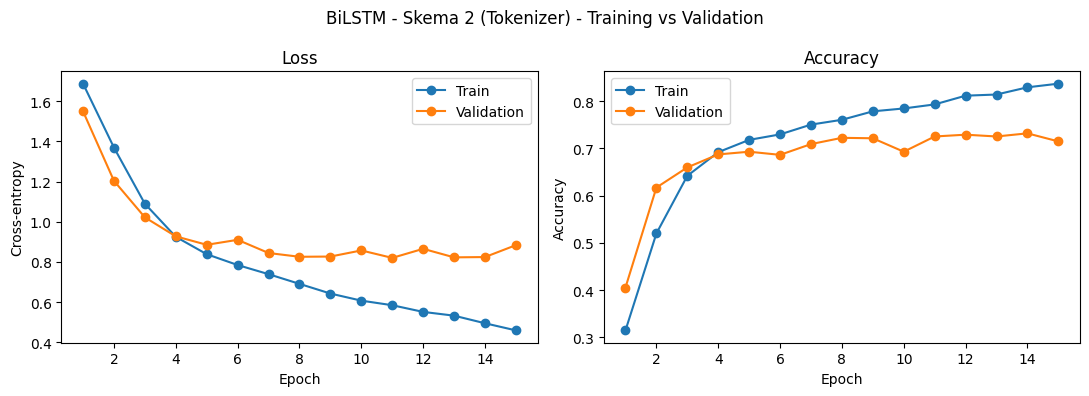

Val loss terendah di epoch 11 (0.8202); epoch terakhir: 0.8836


In [ ]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"],   "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"],   "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("BiLSTM - Skema 2 (Tokenizer) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06b_bilstm_tokenizer_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [ ]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in val_loader:
        preds.append(model(xb.to(device)).argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {(val_df[LABEL_COL] == kelas_terbanyak).mean():.4f}")
print(f"BiLSTM - Skema 2 (Tokenizer) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)] # accuracy ditulis di kolom f1-score (konvensi sklearn)
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
BiLSTM - Skema 2 (Tokenizer) (val): accuracy = 0.7147 | macro-F1 = 0.7197


,precision,recall,f1-score,support
anger,0.839,0.5893,0.6923,168
fear,0.7815,0.6838,0.7294,136
joy,0.7584,0.7143,0.7357,189
love,0.6376,0.8407,0.7252,113
neutral,0.6534,0.7148,0.6827,298
sad,0.7212,0.7881,0.7532,151
accuracy,,,0.7147,1055
macro avg,0.7318,0.7218,0.7197,1055
weighted avg,0.7263,0.7147,0.7144,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,99,8,6,13,34,8
asli_fear,3,93,3,5,24,8
asli_joy,2,2,135,15,27,8
asli_love,1,2,2,95,7,6
asli_neutral,13,12,26,18,213,16
asli_sad,0,2,6,3,21,119


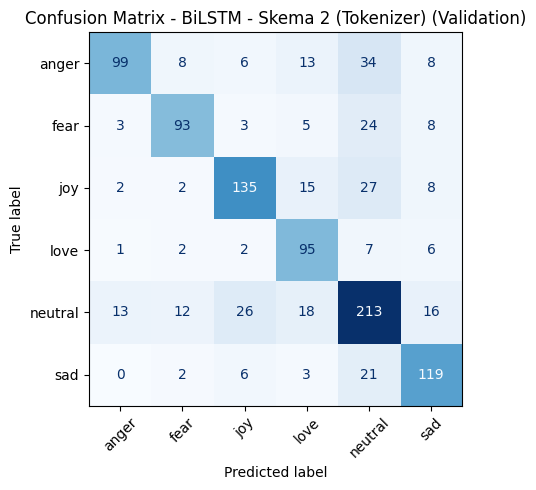

In [ ]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - BiLSTM - Skema 2 (Tokenizer) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06b_bilstm_tokenizer_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [ ]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "BiLSTM", "feature_extraction": "tokenizer", "split": "validation",
                "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
                "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
                "extractor": "tokenizer subword + embedding layer indobenchmark/indobert-base-p1 (beku) -> BiLSTM dilatih",
                "emb_dim": int(EMB_DIM), "max_len": int(MAX_LEN), "vocab_size": int(VOCAB_SIZE),
                "epochs": EPOCHS, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/bilstm_tokenizer_val_results.json


### Notes:
- Vocabulary | MAX_LEN | parameter dilatih: 50000 | 128 | 921,094
- Train acc | Val acc (epoch terakhir): 0.8368 | 0.7147
- Val loss terendah di epoch: epoch ke-11 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.7147 | 0.7197
- Macro-Precision | Macro-Recall: 0.7318 | 0.7218
- F1 tertinggi | terendah per kelas: sad (0.7532) | neutral (0.6827)
- Pasangan kelas yang paling sering tertukar: joy dan neutral (53 kesalahan di dua arah)
- Test set belum disentuh.